# 02 — Exploration de la série

Ce que je veux comprendre avant de modéliser : la forme de la saisonnalité, la présence
éventuelle d'une tendance de fond, la structure d'autocorrélation, et ce qui se passe
autour de 2020-2021.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import preprocessing, plotting
s = preprocessing.serie_hebdo(3, 'PAY')

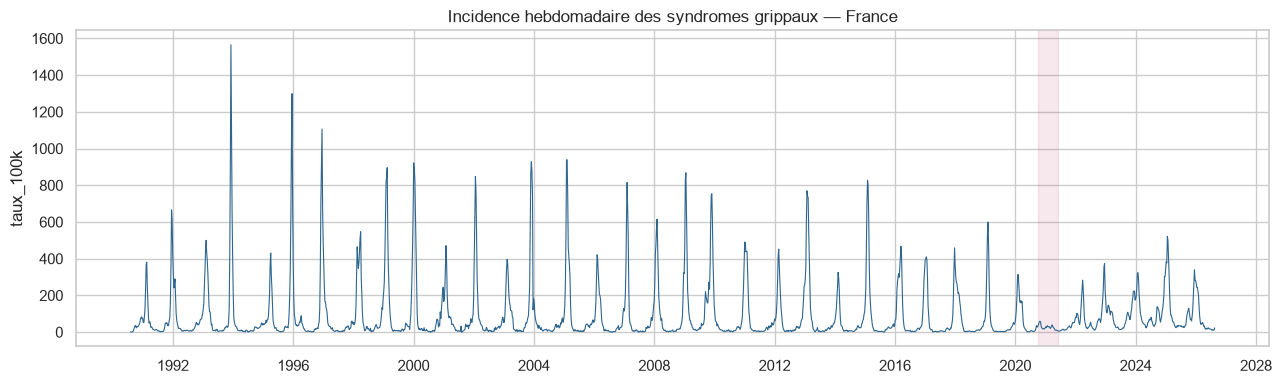

In [2]:
fig = plotting.serie(s, saisons_surlignees=["2020-2021"])
plotting.save(fig, "02_serie_complete")
plt.show()

Chaque hiver, une bouffée épidémique nette, puis retour à un bruit de fond estival bas. Les
pics varient beaucoup d'une année à l'autre (facteur 3 à 5 en amplitude). Et surtout : la
**saison 2020-2021 est quasiment plate** — les mesures contre le COVID (masques,
distanciation, fermetures) ont fait disparaître la grippe cette année-là. C'est une anomalie
qu'aucun modèle entraîné sur l'historique ne peut anticiper ; je m'en servirai comme test de
robustesse au notebook 06.

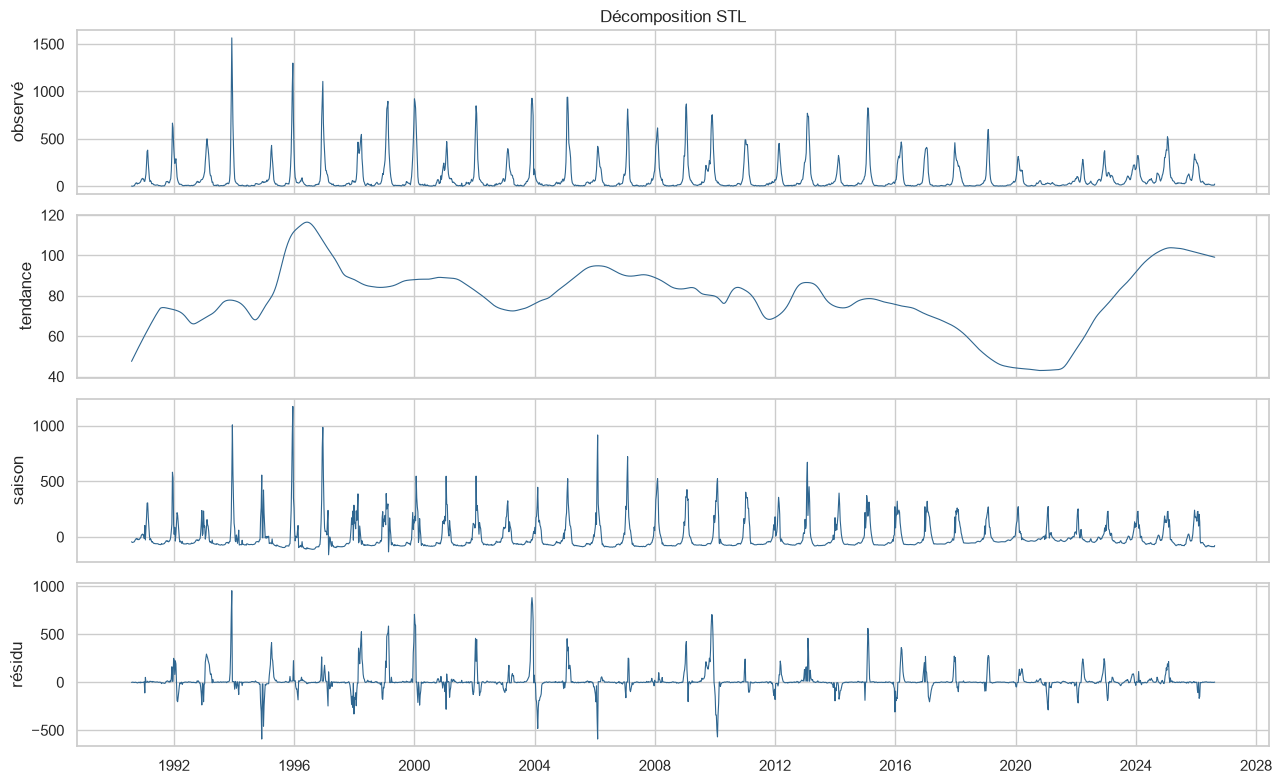

In [3]:
fig = plotting.decomposition(s, period=52)
plotting.save(fig, "02_decomposition_stl")
plt.show()

La décomposition STL confirme : composante saisonnière très marquée et assez régulière,
tendance de fond faible et lente (légère baisse sur la période), résidu dominé par
2020-2021 et par la variabilité d'amplitude des pics.

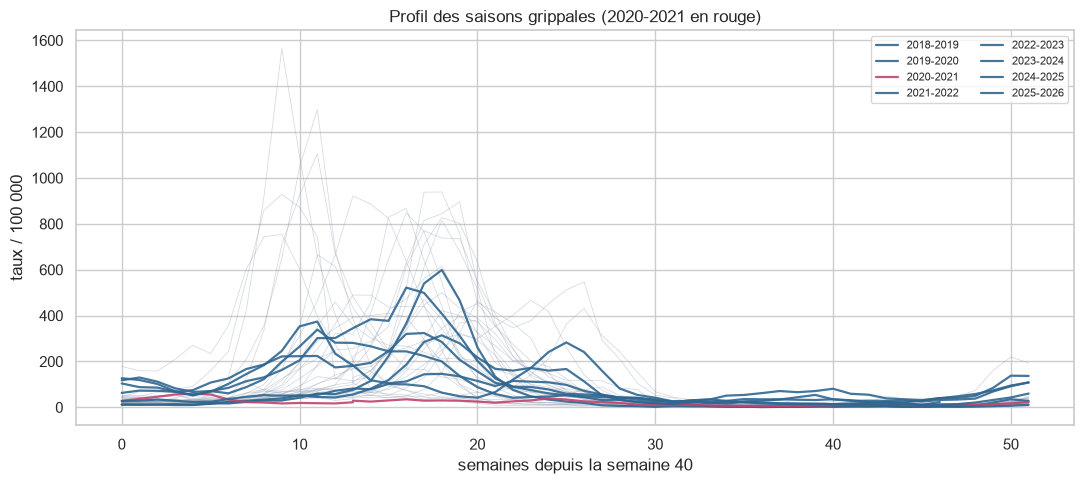

In [4]:
table = preprocessing.table_saisons(s)
fig = plotting.profil_saisonnier(table)
plotting.save(fig, "02_profil_saisonnier")
plt.show()

In [5]:
# Stationnarité (ADF) sur la série brute et sur la série différenciée à 52 semaines.
from statsmodels.tsa.stattools import adfuller
for nom, serie in [("brute", s.dropna()), ("diff. saisonnière (52)", s.diff(52).dropna())]:
    stat, p, *_ = adfuller(serie)
    print(f"ADF {nom:24s} : stat={stat:6.2f}  p={p:.3g}")

ADF brute                    : stat=-11.76  p=1.15e-21
ADF diff. saisonnière (52)   : stat=-15.10  p=7.89e-28


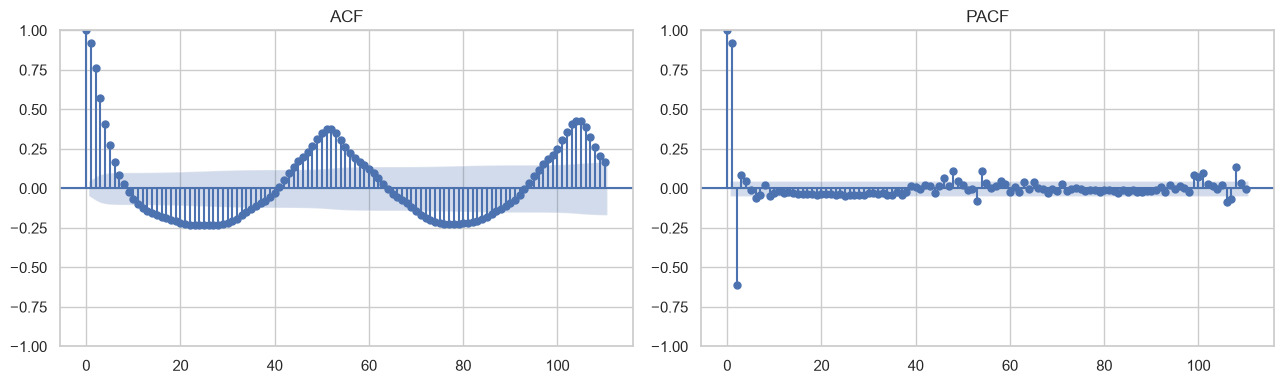

In [6]:
fig = plotting.acf_pacf(s, lags=110)
plotting.save(fig, "02_acf_pacf")
plt.show()

ACF avec un pic net à 52 semaines : la saisonnalité annuelle est l'information dominante.
La différenciation saisonnière rend la série stationnaire (ADF très significatif). Ça
oriente vers un SARIMA avec `D=1` sur la période 52, et quelques termes AR/MA courts pour
la dynamique intra-saison.

In [7]:
pics = preprocessing.pics_par_saison(s)
pics["date_pic"] = pd.to_datetime(pics["date_pic"]).dt.strftime("%Y-%m-%d")
pics.tail(10)

,pic,date_pic,n
saison,,,
2016-2017,410.0,2017-01-16,33
2017-2018,459.0,2017-12-25,33
2018-2019,599.0,2019-02-04,33
2019-2020,314.0,2020-02-03,33
2020-2021,59.0,2020-10-26,34
2021-2022,283.0,2022-03-28,33
2022-2023,374.0,2022-12-19,33
2023-2024,324.0,2024-01-29,33
2024-2025,522.0,2025-01-20,33


Le pic tombe le plus souvent entre fin décembre et mi-février, mais sa date bouge de
plusieurs semaines selon les années, et 2020-2021 n'a pas de pic du tout. Prévoir la date
et la hauteur du pic sera le test le plus exigeant.